# 08 · Fractais: iteração, geometria e convergência
**Objetivo pedagógico:** comparar conjuntos de escape, sistemas de funções iteradas e bacias de Newton; distinguir aparência visual de evidência numérica.

**Luigi Scofano de Araujo · Estudo complementar de Métodos Numéricos**

Material novo, preparado em 2026, seguindo a organização dos roteiros do repositório. Não é uma entrega histórica da disciplina nem reprodução dos notebooks do acervo. Imagens produzidas por cálculo numérico, com cores escolhidas para facilitar a leitura.

Execute em ordem, em kernel novo. Funciona isoladamente em Jupyter/Colab com NumPy e Matplotlib. A célula de configuração controla qualidade e custo; nenhuma conta, API ou dado privado é necessário.

## 1. Configuração e reprodutibilidade
O modo padrão usa 900 × 600 pontos. `QUALIDADE = "alta"` usa 1800 × 1200: quadruplica a memória dos campos e aproximadamente o trabalho por iteração. PNGs são gravados em `figuras_fractais/`, relativamente ao diretório atual. No Colab, esse diretório é temporário: baixe os arquivos antes de encerrar a sessão.

In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

QUALIDADE = "padrao"  # Troque por "alta" para exportação em resolução maior.
LARGURA, ALTURA = (1800, 1200) if QUALIDADE == "alta" else (900, 600)
FIGURAS = Path("figuras_fractais")
FIGURAS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 6.8), "figure.dpi": 110,
                     "axes.grid": False, "font.size": 11})
print("NumPy:", np.__version__, "Matplotlib:", matplotlib.__version__)
print("Malha:", LARGURA, "×", ALTURA)

def malha(limites, largura=LARGURA, altura=ALTURA):
    """A primeira linha corresponde ao menor valor imaginário (origin='lower')."""
    xmin, xmax, ymin, ymax = limites
    if largura < 2 or altura < 2 or not (xmin < xmax and ymin < ymax):
        raise ValueError("Dimensões e limites de malha inválidos.")
    return np.linspace(xmin, xmax, largura)[None, :] + 1j * np.linspace(ymin, ymax, altura)[:, None]

def mostrar(imagem, limites, titulo, arquivo, cmap=None):
    fig, ax = plt.subplots()
    ax.imshow(imagem, extent=limites, origin="lower", cmap=cmap, interpolation="nearest")
    ax.set(xlabel="Parte real / x", ylabel="Parte imaginária / y", title=titulo)
    fig.tight_layout()
    fig.savefig(FIGURAS / arquivo, dpi=180, facecolor="white")
    plt.show()
    plt.close(fig)

NumPy: 2.3.5 Matplotlib: 3.10.8
Malha: 900 × 600


## 2. Mandelbrot, Julia e Burning Ship
Mandelbrot: $z_0=0$, $z_{k+1}=z_k^2+c$; cada pixel representa um **parâmetro** $c$.
Julia: a mesma recorrência, mas $c=-0{,}8+0{,}156i$ é fixo e cada pixel representa uma **condição inicial** $z_0$.
Burning Ship: $z_{k+1}=(|\Re z_k|+i|\Im z_k|)^2+c$, com $z_0=0$.

Usamos raio de escape 4 e até 600 iterações. Nestas janelas, $|c|<4$: depois de $|z|>4$, a desigualdade $|z_{k+1}|\geq |z_k|^2-|c|$ garante crescimento. Preto significa **não escapou dentro do orçamento**, e não pertencimento matematicamente provado.

A implementação mantém apenas índices ativos, evitando atualizar pontos que já escaparam. O contador suavizado colore o tempo de escape; no Burning Ship é uma escolha visual, não um certificado analítico de distância.

mandelbrot : 0.61 s; não escaparam: 119325
julia : 0.18 s; não escaparam: 2435
ship : 0.24 s; não escaparam: 21712


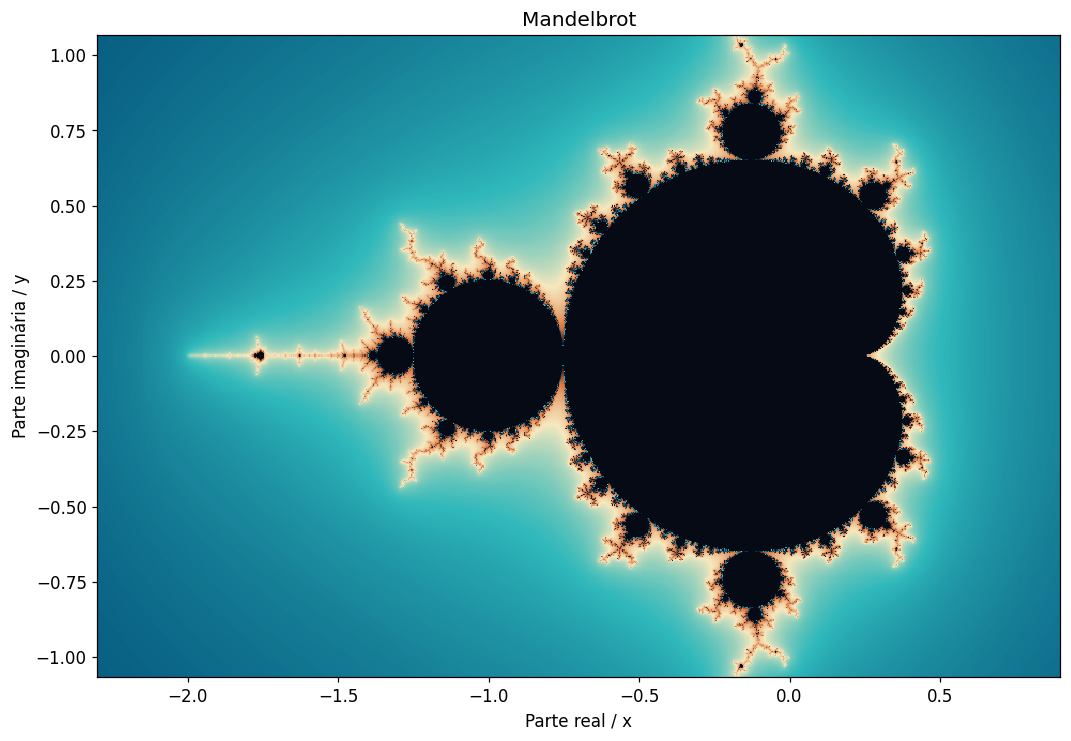

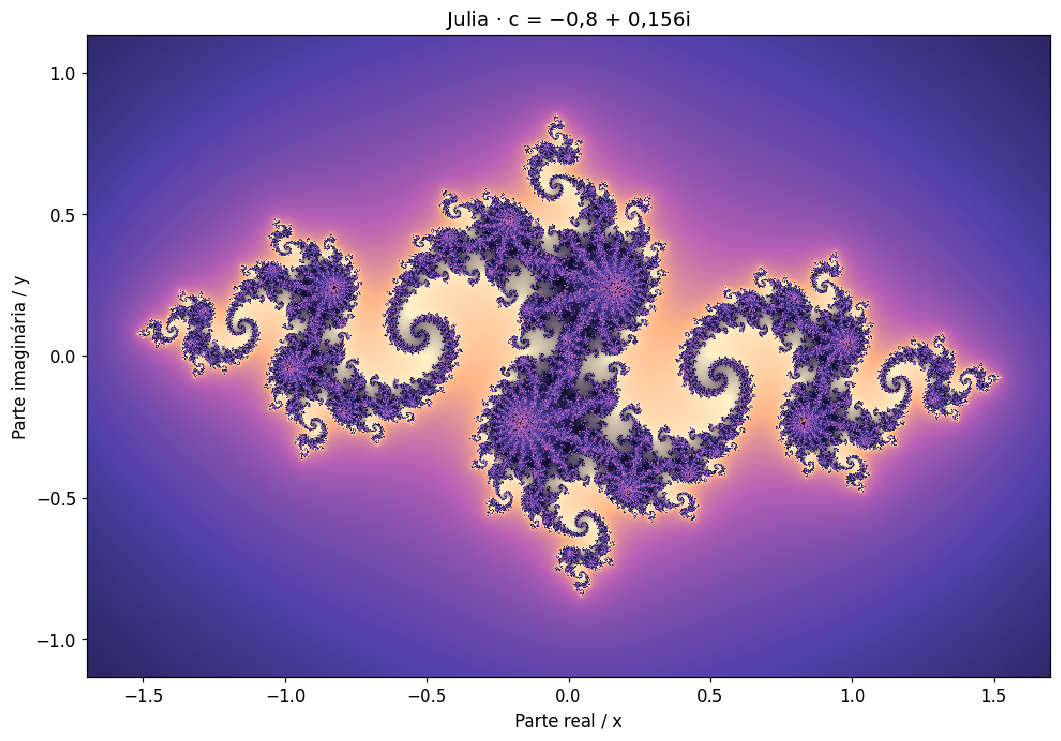

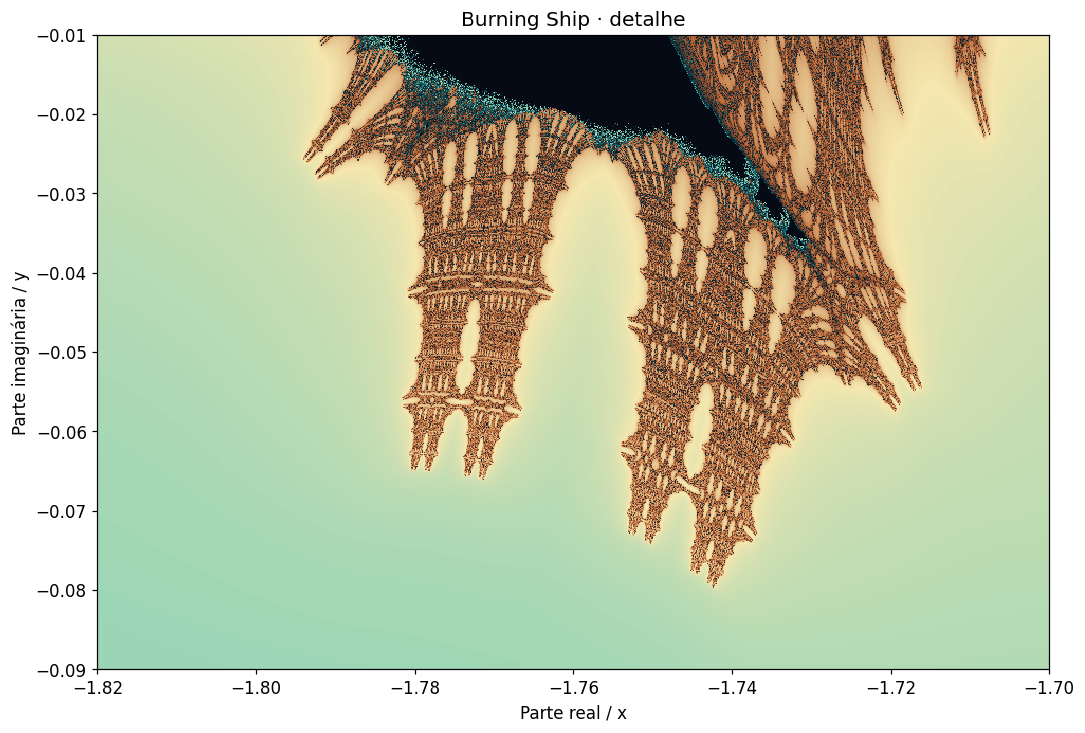

In [2]:
def escape(z_inicial, parametros, maxiter=600, raio=4.0, navio=False):
    """Calcula escape sem iterar pontos já resolvidos; retorna campo e máscara."""
    if maxiter < 1 or raio <= 1:
        raise ValueError("Use maxiter positivo e raio maior que 1.")
    z = np.array(z_inicial, dtype=np.complex128, copy=True)
    c = np.broadcast_to(np.asarray(parametros, complex), z.shape).ravel()
    forma = z.shape
    z = z.ravel()
    ativos = np.arange(z.size)
    tempo = np.zeros(z.size)
    escapou = np.zeros(z.size, dtype=bool)
    for k in range(maxiter):
        valores = z[ativos]
        if navio:
            valores = np.abs(valores.real) + 1j * np.abs(valores.imag)
        valores = valores * valores + c[ativos]
        z[ativos] = valores
        modulo = np.abs(valores)
        saiu = modulo > raio
        indices = ativos[saiu]
        tempo[indices] = k + 1 - np.log2(np.log(modulo[saiu]))
        escapou[indices] = True
        ativos = ativos[~saiu]
        if ativos.size == 0:
            break
    return tempo.reshape(forma), escapou.reshape(forma)

def colorir(tempo, escapou, cores):
    mapa = LinearSegmentedColormap.from_list("fractal", cores)
    intensidade = np.mod(np.log1p(np.maximum(tempo, 0)) * .23, 1)
    rgb = mapa(intensidade)[..., :3]
    rgb[~escapou] = (0.025, .043, .086)
    return rgb

paletas = {
    "mandelbrot": ["#071527", "#075c81", "#2fb8bb", "#f7e8be", "#dc7b44", "#091426"],
    "julia": ["#100f2a", "#5141aa", "#b861b5", "#ffb487", "#fff1c8", "#231945"],
    "ship": ["#071721", "#126a72", "#92d4b7", "#f6e7af", "#b65f30", "#102231"]}
experimentos = [
    ("Mandelbrot", (-2.3, .9, -1.067, 1.067), "mandelbrot"),
    ("Julia · c = −0,8 + 0,156i", (-1.7, 1.7, -1.1333, 1.1333), "julia"),
    ("Burning Ship · detalhe", (-1.82, -1.70, -.09, -.01), "ship")]
resultados = {}
for titulo, limites, tipo in experimentos:
    grade = malha(limites)
    inicio = perf_counter()
    campo, mascara = escape(grade if tipo == "julia" else np.zeros_like(grade),
                            -.8 + .156j if tipo == "julia" else grade, navio=tipo == "ship")
    resultados[tipo] = (campo, mascara)
    print(tipo, ":", round(perf_counter() - inicio, 2), "s; não escaparam:", np.count_nonzero(~mascara))
    mostrar(colorir(campo, mascara, paletas[tipo]), limites, titulo, tipo + ".png")

## 3. Samambaia de Barnsley: funções afins aleatórias
Não usamos escape. Um ponto é transformado repetidamente por $p_{k+1}=A_jp_k+b_j$. As quatro probabilidades são 0,01; 0,85; 0,07; 0,07. A semente fixa permite reproduzir o experimento. O histograma mostra **densidade de visitas**, não uma fotografia botânica.

A geração é sequencial porque cada ponto depende do anterior; pré-sorteamos as escolhas, acumulamos o histograma e descartamos os primeiros 100 pontos. O orçamento padrão é 400 mil pontos (1,6 milhão na qualidade alta).

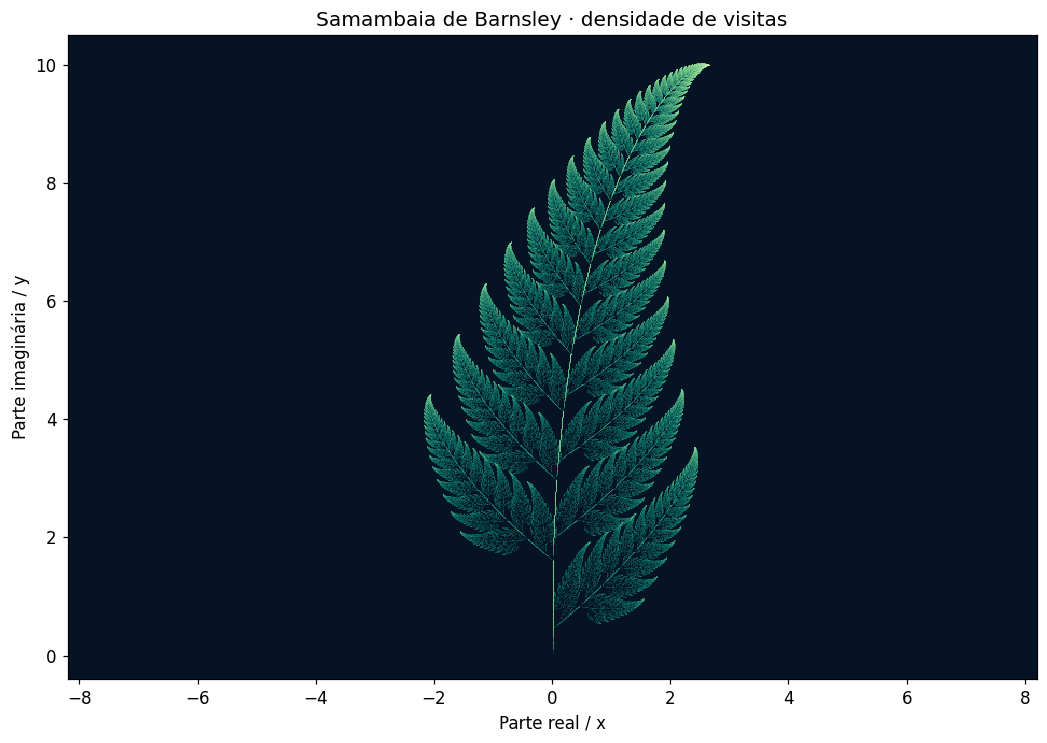

In [3]:
def samambaia(n=400_000, semente=42):
    if n < 101:
        raise ValueError("Use pelo menos 101 pontos.")
    rng = np.random.default_rng(semente)
    escolhas = np.searchsorted([.01, .86, .93, 1.0], rng.random(n))
    pontos = np.empty((n, 2))
    x = y = 0.0
    for i, escolha in enumerate(escolhas):
        if escolha == 0:
            x, y = 0.0, .16 * y
        elif escolha == 1:
            x, y = .85 * x + .04 * y, -.04 * x + .85 * y + 1.6
        elif escolha == 2:
            x, y = .2 * x - .26 * y, .23 * x + .22 * y + 1.6
        else:
            x, y = -.15 * x + .28 * y, .26 * x + .24 * y + .44
        pontos[i] = (x, y)
    return pontos[100:]

pontos = samambaia(1_600_000 if QUALIDADE == "alta" else 400_000)
limites_fern = (-8.2, 8.2, -.4, 10.5)
hist, _, _ = np.histogram2d(pontos[:, 1], pontos[:, 0], bins=(ALTURA, LARGURA),
                            range=[limites_fern[2:], limites_fern[:2]])
verde = LinearSegmentedColormap.from_list("folha", ["#061324", "#0b6b62", "#7ccd8a", "#e7f3b9"])
mostrar(np.log1p(hist), limites_fern, "Samambaia de Barnsley · densidade de visitas", "barnsley.png", verde)
assert int(hist.sum()) == len(pontos)

## 4. Bacias de Newton: raízes de $z^3-1$
A recorrência é $z_{k+1}=z_k-(z_k^3-1)/(3z_k^2)$. Três cores identificam as raízes. Classificamos apenas pontos com resíduo $|z^3-1|<10^{-10}$. Derivada menor que $10^{-14}$, valores não finitos e orçamento esgotado ficam sem classificação. Brilho mostra rapidez, sem substituir o critério de convergência.

Sem convergência certificada: 0


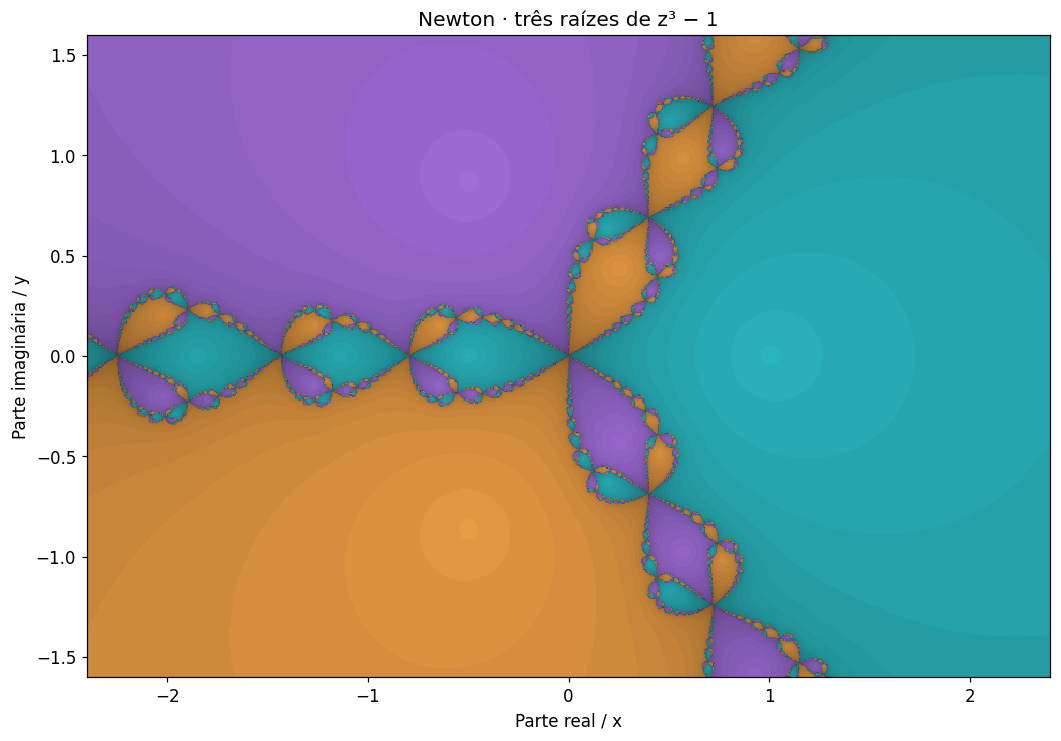

In [4]:
def newton(grade, maxiter=70, tolerancia=1e-10):
    z = np.asarray(grade, complex).copy().ravel()
    raizes = np.exp(2j * np.pi * np.arange(3) / 3)
    rotulos = np.full(z.size, -1, dtype=int)
    passos = np.zeros(z.size, dtype=int)
    ativos = np.arange(z.size)
    for k in range(maxiter + 1):
        valores = z[ativos]
        with np.errstate(over="ignore", invalid="ignore"):
            residuos = np.abs(valores ** 3 - 1)
        convergiu = np.isfinite(residuos) & (residuos < tolerancia)
        indices = ativos[convergiu]
        rotulos[indices] = np.argmin(np.abs(valores[convergiu, None] - raizes), axis=1)
        passos[indices] = k
        ativos = ativos[~convergiu]
        if ativos.size == 0 or k == maxiter:
            break
        derivadas = 3 * z[ativos] ** 2
        validos = np.isfinite(derivadas) & (np.abs(derivadas) > 1e-14)
        ativos, derivadas = ativos[validos], derivadas[validos]
        with np.errstate(over="ignore", invalid="ignore"):
            z[ativos] -= (z[ativos] ** 3 - 1) / derivadas
    return rotulos.reshape(grade.shape), passos.reshape(grade.shape), z.reshape(grade.shape)

limites_newton = (-2.4, 2.4, -1.6, 1.6)
rotulos, passos, finais = newton(malha(limites_newton))
cores_raizes = np.array([[.18, .78, .82], [.68, .47, .93], [1, .67, .29]])
imagem = np.full((*rotulos.shape, 3), .035)
validos = rotulos >= 0
imagem[validos] = cores_raizes[rotulos[validos]] * (.25 + .75 * np.exp(-passos[validos, None] / 24))
mostrar(imagem, limites_newton, "Newton · três raízes de z³ − 1", "newton.png")
print("Sem convergência certificada:", np.count_nonzero(~validos))
assert np.all(np.abs(finais[validos] ** 3 - 1) < 1e-10)

## 5. Verificações numéricas
Asserções verificam casos conhecidos, repetibilidade e contrato de classificação. Não certificam cada detalhe da fronteira ou uma dimensão fractal. A mesma malha deve ser usada ao comparar orçamentos de iteração.

In [5]:
teste = np.array([[0j, -1 + 0j, 2 + 0j]])
_, saiu = escape(np.zeros_like(teste), teste, maxiter=40)
assert np.array_equal(saiu, [[False, False, True]])
assert np.array_equal(samambaia(500), samambaia(500))
r, _, _ = newton(np.array([[1 + 0j, np.exp(2j * np.pi / 3), np.exp(4j * np.pi / 3), 0j]]))
assert np.array_equal(r, [[0, 1, 2, -1]])
g = malha((-2.3, .9, -1.067, 1.067), 150, 100)
_, curto = escape(np.zeros_like(g), g, maxiter=80)
_, longo = escape(np.zeros_like(g), g, maxiter=160)
assert np.all(~curto | longo)  # Escape anterior não pode desaparecer.
print("Testes concluídos: escape, repetibilidade, raízes, singularidade e monotonicidade.")
print("Pixels adicionais que escaparam com 160 iterações:", np.count_nonzero(longo & ~curto))

Testes concluídos: escape, repetibilidade, raízes, singularidade e monotonicidade.
Pixels adicionais que escaparam com 160 iterações: 56


## 6. Interpretação, limitações e exercícios
- **Resolução:** pixels aproximam conjuntos contínuos; aumentar resolução revela detalhes, não prova propriedades geométricas.
- **Precisão:** complex128 usa ponto flutuante de precisão dupla. Zoom extremo perde diferenças entre coordenadas; seria necessária precisão arbitrária, fora deste roteiro.
- **Custo:** escape/Newton custam O(largura × altura × iterações), com redução prática pelo conjunto ativo; Barnsley custa O(pontos). Arrays temporários elevam o pico de memória além dos campos de saída.
- **Cores:** são uma codificação artística de tempo, raiz ou densidade. Não representam energia, temperatura nem erro universal. Os tons das versões anteriores podem variar com resolução e orçamento.
- **Newton:** resíduo é o critério declarado; derivada pequena é limiar absoluto didático, dependente de escala.
- **Exportação:** a cada execução, os mesmos nomes PNG são atualizados. Guarde versões em pastas distintas para comparação.

**Exercícios:** altere apenas c em Julia; compare 300/600/1200 iterações em uma mesma janela; conte pontos não classificados de Newton; compare a densidade de Barnsley com duas sementes e diferentes amostras.

**Evidência esperada:** figuras com domínio, parâmetros e critério de parada; tabela de tempos medida na sua máquina; discussão do que não pode ser concluído só pela imagem.

## Referências conceituais
- Mandelbrot, B. B. *The Fractal Geometry of Nature*. W. H. Freeman, 1982.
- Barnsley, M. F. *Fractals Everywhere*. Academic Press, 1988.
- Peitgen, H.-O.; Jürgens, H.; Saupe, D. *Chaos and Fractals*. Springer, 2004.

Este roteiro complementa `02_zeros_fractais.ipynb`, sem alterar o acervo nem substituir as explicações de convergência daquele estudo.